In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score
import joblib
import os
import json

In [2]:
DATA_PATH = '../data/raw/UCI_Credit_Card.csv'
df = pd.read_csv(DATA_PATH)

df = df.rename(columns={'default.payment.next.month': 'target'})

df = df.drop('ID', axis=1)

print(f"Размер датасета: {df.shape}")
df.head()

Размер датасета: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,target
0,20000.0,2,2,1,24,2,2,-1,-1,-2,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,2,2,2,26,-1,2,0,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,2,2,2,34,0,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,2,2,1,37,0,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1,2,1,57,-1,0,-1,0,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [3]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {X_train.shape}, Test size: {X_test.shape}")

Train size: (24000, 23), Test size: (6000, 23)


In [4]:
model_v1 = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model_v1.fit(X_train, y_train)

preds_v1 = model_v1.predict(X_test)

In [5]:
print("V1")
print(classification_report(y_test, preds_v1))

f1_v1 = f1_score(y_test, preds_v1)
precision_v1 = precision_score(y_test, preds_v1)
recall_v1 = recall_score(y_test, preds_v1)

print(f"F1 Score: {f1_v1:.4f}")
print(f"Precision: {precision_v1:.4f}")
print(f"Recall: {recall_v1:.4f}")

V1
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4673
           1       0.63      0.36      0.46      1327

    accuracy                           0.81      6000
   macro avg       0.73      0.65      0.67      6000
weighted avg       0.79      0.81      0.79      6000

F1 Score: 0.4576
Precision: 0.6293
Recall: 0.3595


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_v2 = LogisticRegression(max_iter=1000, random_state=42)
model_v2.fit(X_train_scaled, y_train)

preds_v2 = model_v2.predict(X_test_scaled)

print("--- Модель v2 (Тестовая) ---")
print(classification_report(y_test, preds_v2))

f1_v2 = f1_score(y_test, preds_v2)
precision_v2 = precision_score(y_test, preds_v2)
recall_v2 = recall_score(y_test, preds_v2)

--- Модель v2 (Тестовая) ---
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4673
           1       0.69      0.24      0.36      1327

    accuracy                           0.81      6000
   macro avg       0.75      0.60      0.62      6000
weighted avg       0.79      0.81      0.77      6000



In [7]:

os.makedirs('../models', exist_ok=True)


joblib.dump(model_v1, '../models/model_v1.joblib')

joblib.dump(model_v2, '../models/model_v2.joblib')
joblib.dump(scaler, '../models/scaler_v2.joblib')


feature_names = X.columns.tolist()
with open('../models/feature_names.json', 'w') as f:
    json.dump(feature_names, f)

print("Save on ../models/")

Save on ../models/


ROC-AUC модели v1 (Случайный лес): 0.7513
ROC-AUC модели v2 (Логистическая регрессия): 0.7076
--------------------------------------------------


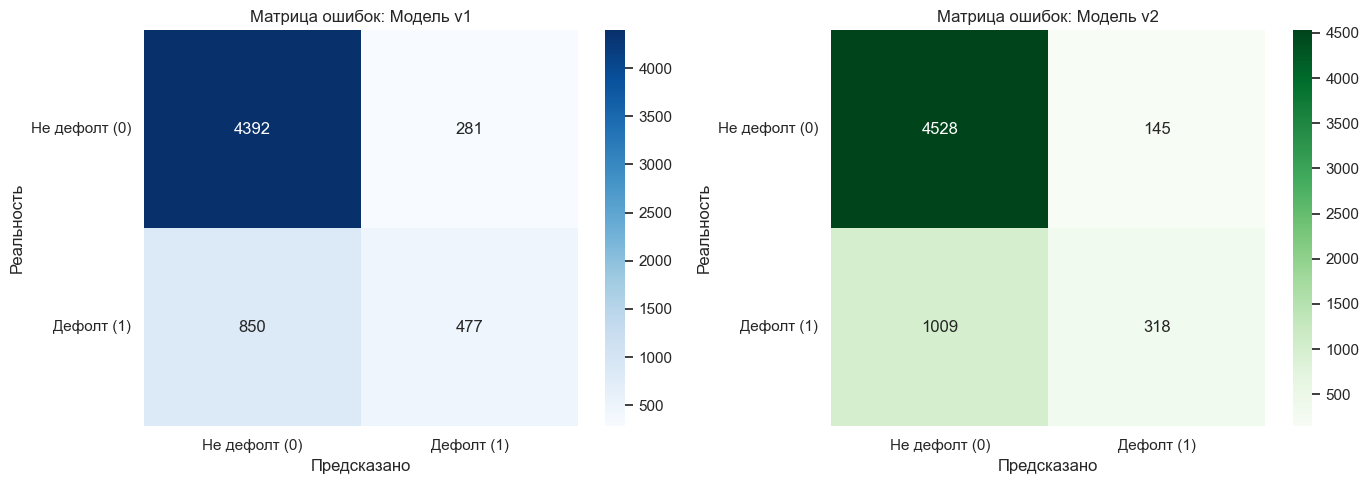

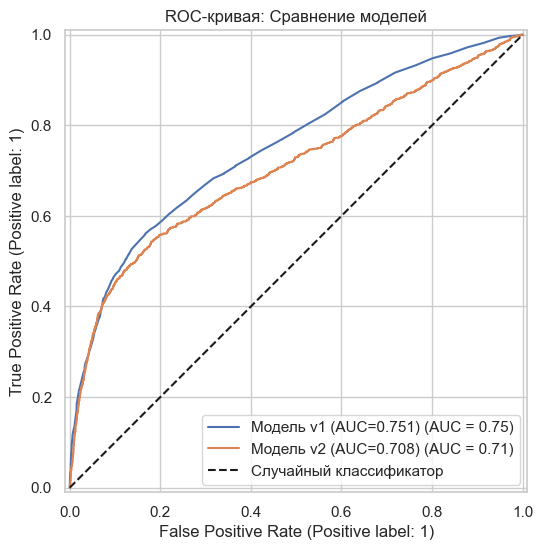

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)


scaler_v2 = joblib.load('../models/scaler_v2.joblib')
model_v1 = joblib.load('../models/model_v1.joblib')
model_v2 = joblib.load('../models/model_v2.joblib')

preds_v1 = model_v1.predict(X_test)
preds_v2 = model_v2.predict(scaler_v2.transform(X_test))

sns.set_theme(style="whitegrid")

# ROC-AUC
proba_v1 = model_v1.predict_proba(X_test)[:, 1]
roc_auc_v1 = roc_auc_score(y_test, proba_v1)

proba_v2 = model_v2.predict_proba(scaler_v2.transform(X_test))[:, 1]
roc_auc_v2 = roc_auc_score(y_test, proba_v2)

print(f"ROC-AUC модели v1 (Случайный лес): {roc_auc_v1:.4f}")
print(f"ROC-AUC модели v2 (Логистическая регрессия): {roc_auc_v2:.4f}")
print("-" * 50)

# ошибки
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_v1 = confusion_matrix(y_test, preds_v1)
sns.heatmap(cm_v1, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title('Матрица ошибок: Модель v1')
axes[0].set_xlabel('Предсказано')
axes[0].set_ylabel('Реальность')
axes[0].set_yticklabels(['Не дефолт (0)', 'Дефолт (1)'], rotation=0)
axes[0].set_xticklabels(['Не дефолт (0)', 'Дефолт (1)'])

cm_v2 = confusion_matrix(y_test, preds_v2)
sns.heatmap(cm_v2, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title('Матрица ошибок: Модель v2')
axes[1].set_xlabel('Предсказано')
axes[1].set_ylabel('Реальность')
axes[1].set_yticklabels(['Не дефолт (0)', 'Дефолт (1)'], rotation=0)
axes[1].set_xticklabels(['Не дефолт (0)', 'Дефолт (1)'])

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_predictions(y_test, proba_v1, name=f"Модель v1 (AUC={roc_auc_v1:.3f})", ax=ax)
RocCurveDisplay.from_predictions(y_test, proba_v2, name=f"Модель v2 (AUC={roc_auc_v2:.3f})", ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Случайный классификатор")
ax.set_title("ROC-кривая: Сравнение моделей")
ax.legend(loc="lower right")
plt.show()